# 03a — Feature Dataset Exploration (Full Period)

**Goal:** explore the **windowed feature dataset** built in NB02a (350 s windows, min / max / mean / sum per analog sensor, active_s / flips per binary sensor) over the full period (Jun 2024 – Jun 2025), before it is clustered in NB04. NB01 explores the raw 1 Hz data; this notebook explores the features made from it.

**No model is used here.** The baseline models (RF, LSTM-AE) and their scores are analysed separately in NB03b.

**Sections:**
1. Data loading (feature windows, train + test)
2. Feature discriminability per documented sensor group (Cohen's d, per period)
3. Within- vs cross-group correlation of sensor pairs
4. Feature aggregation redundancy (min / max / mean / sum, active_s / flips) → used by NB04 to drop `_sum`
5. Temporal coverage

In [1]:
import os, gc, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

ROOT = os.path.abspath('..')
OUT_DIR = os.path.join(ROOT, 'outputs')
NB03A_OUT = os.path.join(OUT_DIR, 'nb03a_artifacts')
os.makedirs(NB03A_OUT, exist_ok=True)

WINDOW_S = 350
SPLIT_DATE = pd.Timestamp('2025-02-12')

print('Setup complete')

Setup complete


## 1. Data Loading — Feature Windows (Full Period)

The train and test feature files from NB02a, combined into one table. The period of a window is its source file (the official MetroAT `train/` and `test/` folders), the same rule as NB02a, NB03b and NB04. The last train-file window ends at 2025-02-12 00:05, a few minutes after the split date, and stays in train.

In [2]:
train_sup = pd.read_parquet(os.path.join(OUT_DIR, 'supervised', 'train.parquet'))
test_sup = pd.read_parquet(os.path.join(OUT_DIR, 'supervised', 'test.parquet'))
feature_cols = [c for c in train_sup.columns if c not in {'timestamp', 'window_end', 'label'}]

train_sup['split'], test_sup['split'] = 'train', 'test'  # period = source file (official MetroAT split, as in NB02a and NB04)
feats_all = pd.concat([train_sup[feature_cols + ['label', 'window_end', 'split']],
                       test_sup[feature_cols + ['label', 'window_end', 'split']]]).sort_values('window_end').reset_index(drop=True)
feats_all['window_end'] = pd.to_datetime(feats_all['window_end'])
del train_sup, test_sup; gc.collect()

print(f'Feature windows, full period: {len(feats_all):,} ({len(feature_cols)} features)')
print(f'  Train: {(feats_all["split"]=="train").sum():,} | Test: {(feats_all["split"]=="test").sum():,}')
print(f'  Date range: {feats_all["window_end"].min()} to {feats_all["window_end"].max()}')
print(f'  Failure windows (label = 1: failure running or starting within 6.2 h): {feats_all["label"].sum():,} '
      f'({100*feats_all["label"].mean():.2f}%)')
for sp in ('train', 'test'):
    l = feats_all.loc[feats_all['split'] == sp, 'label']
    print(f'    {sp}: {l.sum():,} ({100*l.mean():.2f}%)')

Feature windows, full period: 64,522 (340 features)
  Train: 41,375 | Test: 23,147
  Date range: 2024-06-01 04:41:40 to 2025-07-01 00:04:10
  Failure windows (label = 1: failure running or starting within 6.2 h): 1,202 (1.86%)
    train: 533 (1.29%)
    test: 669 (2.89%)


## 2. Feature Discriminability per Documented Sensor Group

For each feature, Cohen's d between normal and failure windows (6.2 h-shifted label: pre-failure + in-failure windows). Because failure windows are concentrated in the drifted test period (see NB03b §3 and NB04 §4.6), d is computed **within the train period and within the test period separately**. The **robust d** = min(d_train, d_test) only credits effects that appear in both periods.

Features are grouped by the **documented sensor-group schema** of the MetroAT documentation (`src/config.py`: APU, Brake, Leveling, Traction, Context). These groups describe sensors, not the data-driven clusters of NB04, which stay unlabelled. The two asset-history features (days since last failure / revision) are not sensors, get no group and are left out of the group summaries.

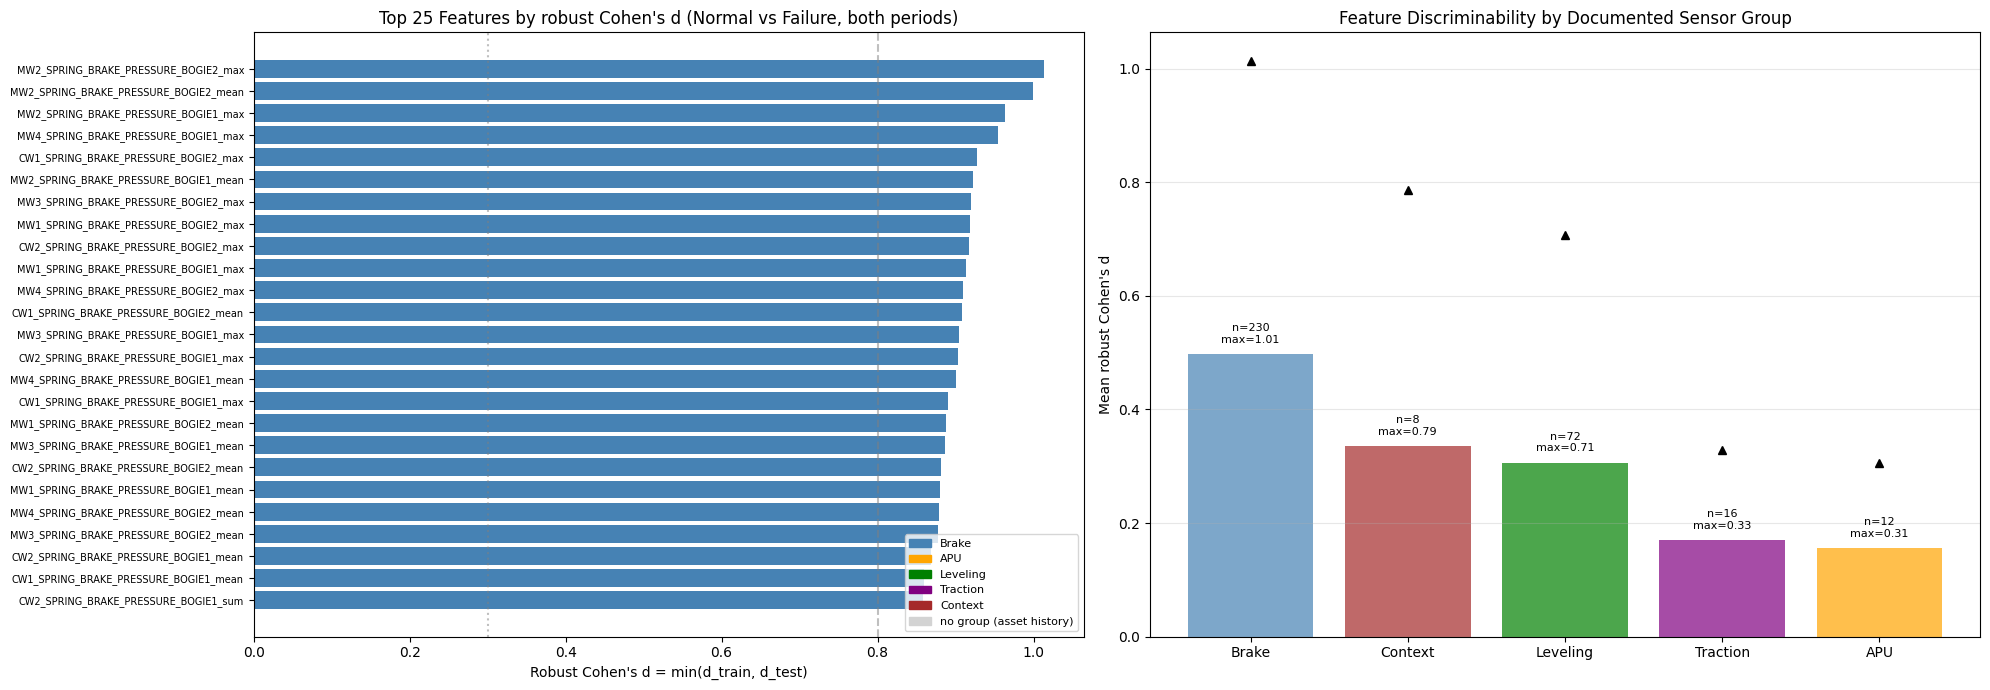

Features with d > 0.3 (at least small effect): pooled vs robust (both periods)
  Pooled (train+test mixed): 268 / 340
  Train only: 288 | Test only: 238
Robust d > 0.3:
  Total: 234 / 340
  Brake: 189/230 features
  Context: 3/8 features
  Leveling: 39/72 features
  Traction: 2/16 features
  APU: 1/12 features

Mean robust Cohen's d per sensor group:
               mean    median       max  count
subsystem                                     
Brake      0.497450  0.512494  1.013646    230
Context    0.335852  0.137851  0.786685      8
Leveling   0.306124  0.328075  0.707619     72
Traction   0.169998  0.193544  0.328260     16
APU        0.155486  0.148078  0.306464     12


In [3]:
# Documented sensor-group schema (MetroAT documentation, src/config.py). The two asset-history features
# (days since last failure / revision) are not sensors and get no group; they are left out of group summaries.
import sys
sys.path.insert(0, ROOT)
from src.config import SUBSYSTEMS
SENSOR_GROUP = {s: g for g, sensors in SUBSYSTEMS.items() for s in sensors}
NO_GROUP = 'no group (asset history)'
AGG_SUFFIXES = ('_active_s', '_min', '_max', '_mean', '_sum', '_flips')


def sensor_of(f):
    for suf in AGG_SUFFIXES:
        if f.endswith(suf):
            return f[:-len(suf)]
    return f


def get_subsystem(name):
    return SENSOR_GROUP.get(sensor_of(name), NO_GROUP)

# Cohen's d per feature, within each period (controls for the train/test shift)
period = np.where(feats_all['window_end'] < SPLIT_DATE, 'train', 'test')
normal = feats_all[feats_all['label'] == 0]
failure = feats_all[feats_all['label'] == 1]


def cohen_d(n_vals, f_vals):
    n_vals, f_vals = n_vals.dropna(), f_vals.dropna()
    if len(n_vals) < 10 or len(f_vals) < 10 or n_vals.std() == 0:
        return 0.0
    pooled = np.sqrt((n_vals.var() * (len(n_vals) - 1) + f_vals.var() * (len(f_vals) - 1)) / (len(n_vals) + len(f_vals) - 2))
    return abs(f_vals.mean() - n_vals.mean()) / pooled if pooled > 0 else 0.0


masks = {p: period == p for p in ('train', 'test')}
lab = feats_all['label'].values
cohens_d = []
for col in feature_cols:
    x = feats_all[col]
    d_pooled = cohen_d(x[lab == 0], x[lab == 1])
    d_tr = cohen_d(x[masks['train'] & (lab == 0)], x[masks['train'] & (lab == 1)])
    d_te = cohen_d(x[masks['test'] & (lab == 0)], x[masks['test'] & (lab == 1)])
    cohens_d.append({'feature': col, 'cohens_d_pooled': d_pooled, 'cohens_d_train': d_tr, 'cohens_d_test': d_te,
                     'cohens_d': min(d_tr, d_te), 'subsystem': get_subsystem(col)})
cd_df = pd.DataFrame(cohens_d).sort_values('cohens_d', ascending=False).reset_index(drop=True)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(20, 7))

# Top 25 features by Cohen's d
ax = axes[0]
top25 = cd_df.head(25)
colors_map = {'Brake': 'steelblue', 'APU': 'orange', 'Leveling': 'green',
              'Traction': 'purple', 'Context': 'brown', NO_GROUP: 'lightgray'}
ax.barh(range(len(top25)), top25['cohens_d'].values,
        color=[colors_map.get(s, 'gray') for s in top25['subsystem']])
ax.set_yticks(range(len(top25)))
ax.set_yticklabels(top25['feature'].values, fontsize=7)
ax.invert_yaxis()
ax.set_xlabel("Robust Cohen's d = min(d_train, d_test)")
ax.set_title('Top 25 Features by robust Cohen\'s d (Normal vs Failure, both periods)')
ax.axvline(0.3, color='gray', linestyle=':', alpha=0.5, label='small effect (0.3)')
ax.axvline(0.8, color='gray', linestyle='--', alpha=0.5, label='large effect (0.8)')
legend_patches = [Patch(color=c, label=s) for s, c in colors_map.items()]
ax.legend(handles=legend_patches, loc='lower right', fontsize=8)

# Cohen's d by subsystem
ax = axes[1]
sub_cd = cd_df[cd_df['subsystem'] != NO_GROUP].groupby('subsystem')['cohens_d'].agg(['mean', 'median', 'max', 'count'])
sub_cd = sub_cd.sort_values('mean', ascending=False)
x = list(range(len(sub_cd)))
ax.bar(x, sub_cd['mean'], color=[colors_map.get(s, 'gray') for s in sub_cd.index], alpha=0.7)
for i, (idx, row) in enumerate(sub_cd.iterrows()):
    ax.plot(i, row['max'], 'k^', markersize=6)
    ax.text(i, row['mean'] + 0.02, f'n={int(row["count"])}\nmax={row["max"]:.2f}', 
            ha='center', fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(sub_cd.index)
ax.set_ylabel("Mean robust Cohen's d")
ax.set_title('Feature Discriminability by Documented Sensor Group')
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

# Summary
print('Features with d > 0.3 (at least small effect): pooled vs robust (both periods)')
print(f"  Pooled (train+test mixed): {(cd_df['cohens_d_pooled'] > 0.3).sum()} / {len(cd_df)}")
print(f"  Train only: {(cd_df['cohens_d_train'] > 0.3).sum()} | Test only: {(cd_df['cohens_d_test'] > 0.3).sum()}")
print('Robust d > 0.3:')
sig = cd_df[cd_df['cohens_d'] > 0.3]
print(f'  Total: {len(sig)} / {len(cd_df)}')
for sub in sig['subsystem'].unique():
    n = (sig['subsystem'] == sub).sum()
    total = (cd_df['subsystem'] == sub).sum()
    print(f'  {sub}: {n}/{total} features')

print(f'\nMean robust Cohen\'s d per sensor group:')
print(sub_cd[['mean', 'median', 'max', 'count']].to_string())

## 3. Within-Group Correlation Analysis

Do features of sensors in the same documented group correlate more strongly than features across groups? Pairs of aggregations of the **same physical sensor** (e.g. min/max/mean/sum of one channel) are excluded, because they are correlated by construction. The plot shows the distribution over all sensor pairs in normal windows; the table below it gives the mean, median and the share of nearly unrelated (|r| < 0.2) and nearly synchronous (|r| > 0.8) pairs.

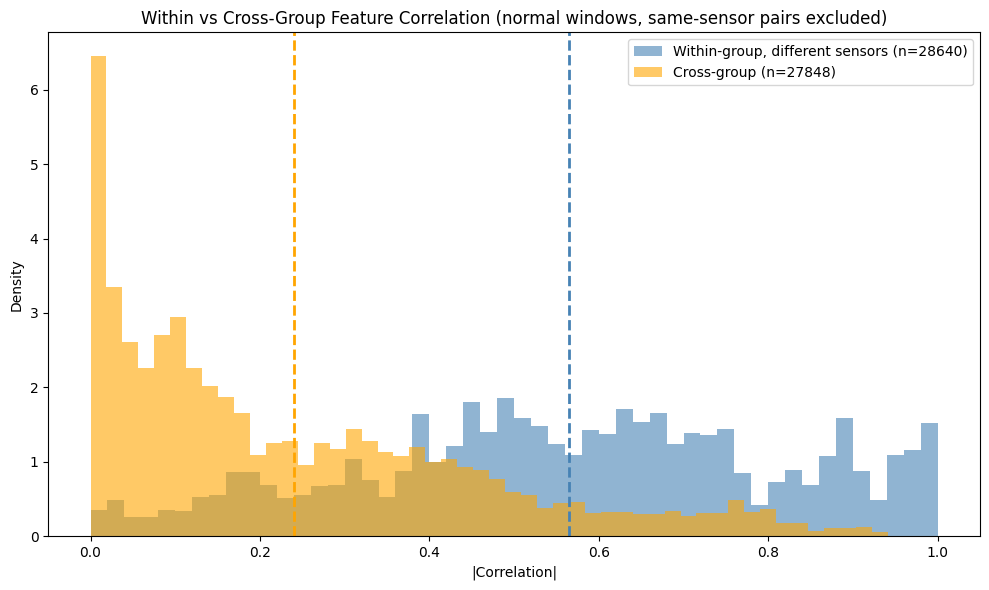

                n pairs    mean  median  |r| < 0.2  |r| > 0.8
Within-group      28640   0.565   0.572       10%       20%
Cross-group       27848   0.240   0.170       54%        2%
Ratio of means: 2.3x | ratio of medians: 3.4x


In [4]:
# Cross-subsystem correlation (sample to keep it fast)
sample_n = min(5000, len(normal))
normal_sample = normal[feature_cols].sample(sample_n, random_state=42)
full_corr = normal_sample.corr().abs()

within_vals, cross_vals = [], []
for i, c1 in enumerate(feature_cols):
    for j, c2 in enumerate(feature_cols):
        if j <= i:
            continue
        val = full_corr.loc[c1, c2]
        if sensor_of(c1) == sensor_of(c2):
            continue  # same physical sensor: correlated by construction
        if NO_GROUP in (get_subsystem(c1), get_subsystem(c2)):
            continue  # asset-history features belong to no sensor group
        if get_subsystem(c1) == get_subsystem(c2):
            within_vals.append(val)
        else:
            cross_vals.append(val)

# Within vs cross-group distribution (normal windows)
within_arr = np.array(within_vals)[~np.isnan(within_vals)]
cross_arr = np.array(cross_vals)[~np.isnan(cross_vals)]

fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(within_arr, bins=50, alpha=0.6, color='steelblue', label=f'Within-group, different sensors (n={len(within_arr)})', density=True)
ax.hist(cross_arr, bins=50, alpha=0.6, color='orange', label=f'Cross-group (n={len(cross_arr)})', density=True)
ax.axvline(within_arr.mean(), color='steelblue', linestyle='--', linewidth=2)
ax.axvline(cross_arr.mean(), color='orange', linestyle='--', linewidth=2)
ax.set_xlabel('|Correlation|')
ax.set_ylabel('Density')
ax.set_title('Within vs Cross-Group Feature Correlation (normal windows, same-sensor pairs excluded)')
ax.legend()
plt.tight_layout()
plt.show()

print(f'{"":<14}{"n pairs":>9}{"mean":>8}{"median":>8}{"|r| < 0.2":>11}{"|r| > 0.8":>11}')
for name, v in (('Within-group', within_arr), ('Cross-group', cross_arr)):
    print(f'{name:<14}{len(v):>9}{v.mean():>8.3f}{np.median(v):>8.3f}{(v < 0.2).mean():>10.0%}{(v > 0.8).mean():>10.0%}')
print(f'Ratio of means: {within_arr.mean()/cross_arr.mean():.1f}x | ratio of medians: {np.median(within_arr)/np.median(cross_arr):.1f}x')


## 4. Feature Aggregation Redundancy Analysis

Each analog sensor produces 4 windowed features (`min`, `max`, `mean`, `sum`) and each binary sensor 2 (`active_s`, `flips`). Some are nearly redundant by construction: `sum = mean × number of rows in the window`, so the two differ only when windows have missing rows. 

**Question:** Which aggregations carry unique information and which are redundant? This informs whether we should reduce the feature set before clustering in NB04.

Sensors analyzed: 95
Sensors with multiple aggregations: 95

Pair                   Mean |r|   Median |r|   % > 0.95   % > 0.80  N sensors
---------------------------------------------------------------------------
_active_s vs _flips       0.563        0.685       0.0%       0.0%         21
_max vs _mean             0.696        0.740       6.8%      39.2%         74
_max vs _min              0.383        0.426       1.4%       5.4%         74
_max vs _sum              0.624        0.642       1.4%       8.1%         74
_mean vs _min             0.779        0.782       1.4%      45.9%         74
_mean vs _sum             0.893        0.968      60.8%      83.8%         74
_min vs _sum              0.676        0.621       1.4%      35.1%         74


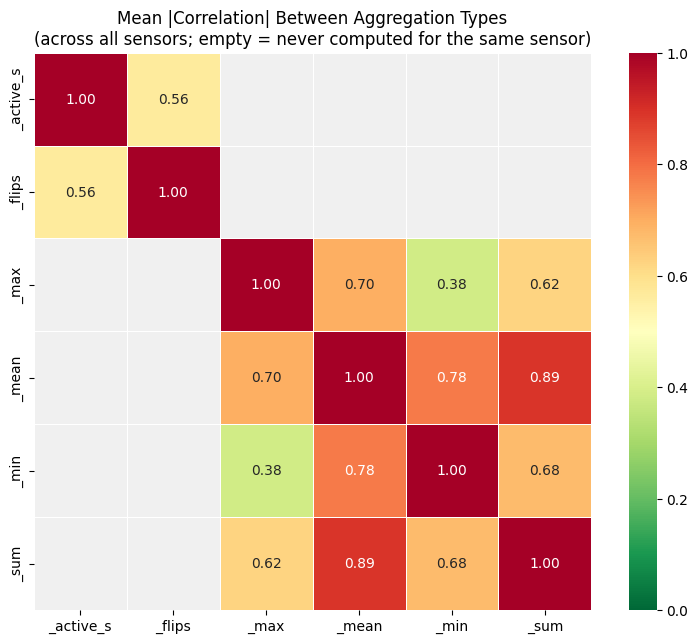


--- REDUNDANCY VERDICT ---
  _active_s vs _flips  → MODERATELY CORRELATED — keep both
  _max vs _mean        → MODERATELY CORRELATED — keep both
  _max vs _min         → INDEPENDENT — keep both
  _max vs _sum         → MODERATELY CORRELATED — keep both
  _mean vs _min        → MODERATELY CORRELATED — keep both
  _mean vs _sum        → HIGHLY CORRELATED — consider dropping
  _min vs _sum         → MODERATELY CORRELATED — keep both


In [5]:
# ── Aggregation Redundancy Analysis ──
# For each physical sensor, compute pairwise correlation between its aggregations

SUFFIXES = ['_active_s', '_min', '_max', '_mean', '_sum', '_flips']

# Extract sensor -> list of (suffix, feature_name) mapping
sensor_aggs = {}
for f in feature_cols:
    for suf in SUFFIXES:
        if f.endswith(suf):
            sensor = f[:-len(suf)]
            sensor_aggs.setdefault(sensor, {})[suf] = f
            break

# Sample data for correlation computation
sample_n = min(10000, len(feats_all))
sample = feats_all[feature_cols].sample(sample_n, random_state=42)

# Compute pairwise |correlation| between aggregations for each sensor
pair_corrs = {}  # (suf1, suf2) -> list of correlations
for sensor, aggs in sensor_aggs.items():
    if len(aggs) < 2:
        continue
    sufs = sorted(aggs.keys())
    for i, s1 in enumerate(sufs):
        for s2 in sufs[i+1:]:
            r = sample[aggs[s1]].corr(sample[aggs[s2]])
            pair = (s1, s2)
            pair_corrs.setdefault(pair, []).append(abs(r))

# Summary table
print(f'Sensors analyzed: {len(sensor_aggs)}')
print(f'Sensors with multiple aggregations: {sum(1 for v in sensor_aggs.values() if len(v) >= 2)}')
print(f'\n{"Pair":<20} {"Mean |r|":>10} {"Median |r|":>12} {"% > 0.95":>10} {"% > 0.80":>10} {"N sensors":>10}')
print('-' * 75)

import numpy as np
pair_summary = []
for (s1, s2), vals in sorted(pair_corrs.items()):
    vals = np.array(vals)
    pair_label = f'{s1} vs {s2}'
    pct_95 = 100 * (vals > 0.95).mean()
    pct_80 = 100 * (vals > 0.80).mean()
    print(f'{pair_label:<20} {vals.mean():>10.3f} {np.median(vals):>12.3f} {pct_95:>9.1f}% {pct_80:>9.1f}% {len(vals):>10}')
    pair_summary.append({
        'pair': pair_label, 'mean_corr': vals.mean(), 'median_corr': np.median(vals),
        'pct_above_95': pct_95, 'pct_above_80': pct_80, 'n_sensors': len(vals)
    })

# Visualize: heatmap of mean correlation between aggregation types.
# Pairs that never occur for the same sensor (binary active_s/flips vs analog min/max/mean/sum) stay empty.
agg_types = sorted(set(s for pair in pair_corrs.keys() for s in pair))
corr_matrix = pd.DataFrame(np.nan, index=agg_types, columns=agg_types)
for t in agg_types:
    corr_matrix.loc[t, t] = 1.0
for (s1, s2), vals in pair_corrs.items():
    corr_matrix.loc[s1, s2] = np.mean(vals)
    corr_matrix.loc[s2, s1] = np.mean(vals)

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='RdYlGn_r', vmin=0, vmax=1,
            ax=ax, square=True, linewidths=0.5)
ax.set_facecolor('#f0f0f0')
ax.set_title('Mean |Correlation| Between Aggregation Types\n(across all sensors; empty = never computed for the same sensor)')
plt.tight_layout()
plt.savefig(os.path.join(NB03A_OUT, 'aggregation_redundancy.png'), dpi=150, bbox_inches='tight')
plt.show()

# Identify which pairs are truly redundant (>95% of sensors have |r| > 0.95)
print('\n--- REDUNDANCY VERDICT ---')
for row in pair_summary:
    if row['pct_above_95'] > 90:
        status = 'REDUNDANT — drop one'
    elif row['pct_above_80'] > 80:
        status = 'HIGHLY CORRELATED — consider dropping'
    elif row['mean_corr'] > 0.5:
        status = 'MODERATELY CORRELATED — keep both'
    else:
        status = 'INDEPENDENT — keep both'
    print(f'  {row["pair"]:<20} → {status}')

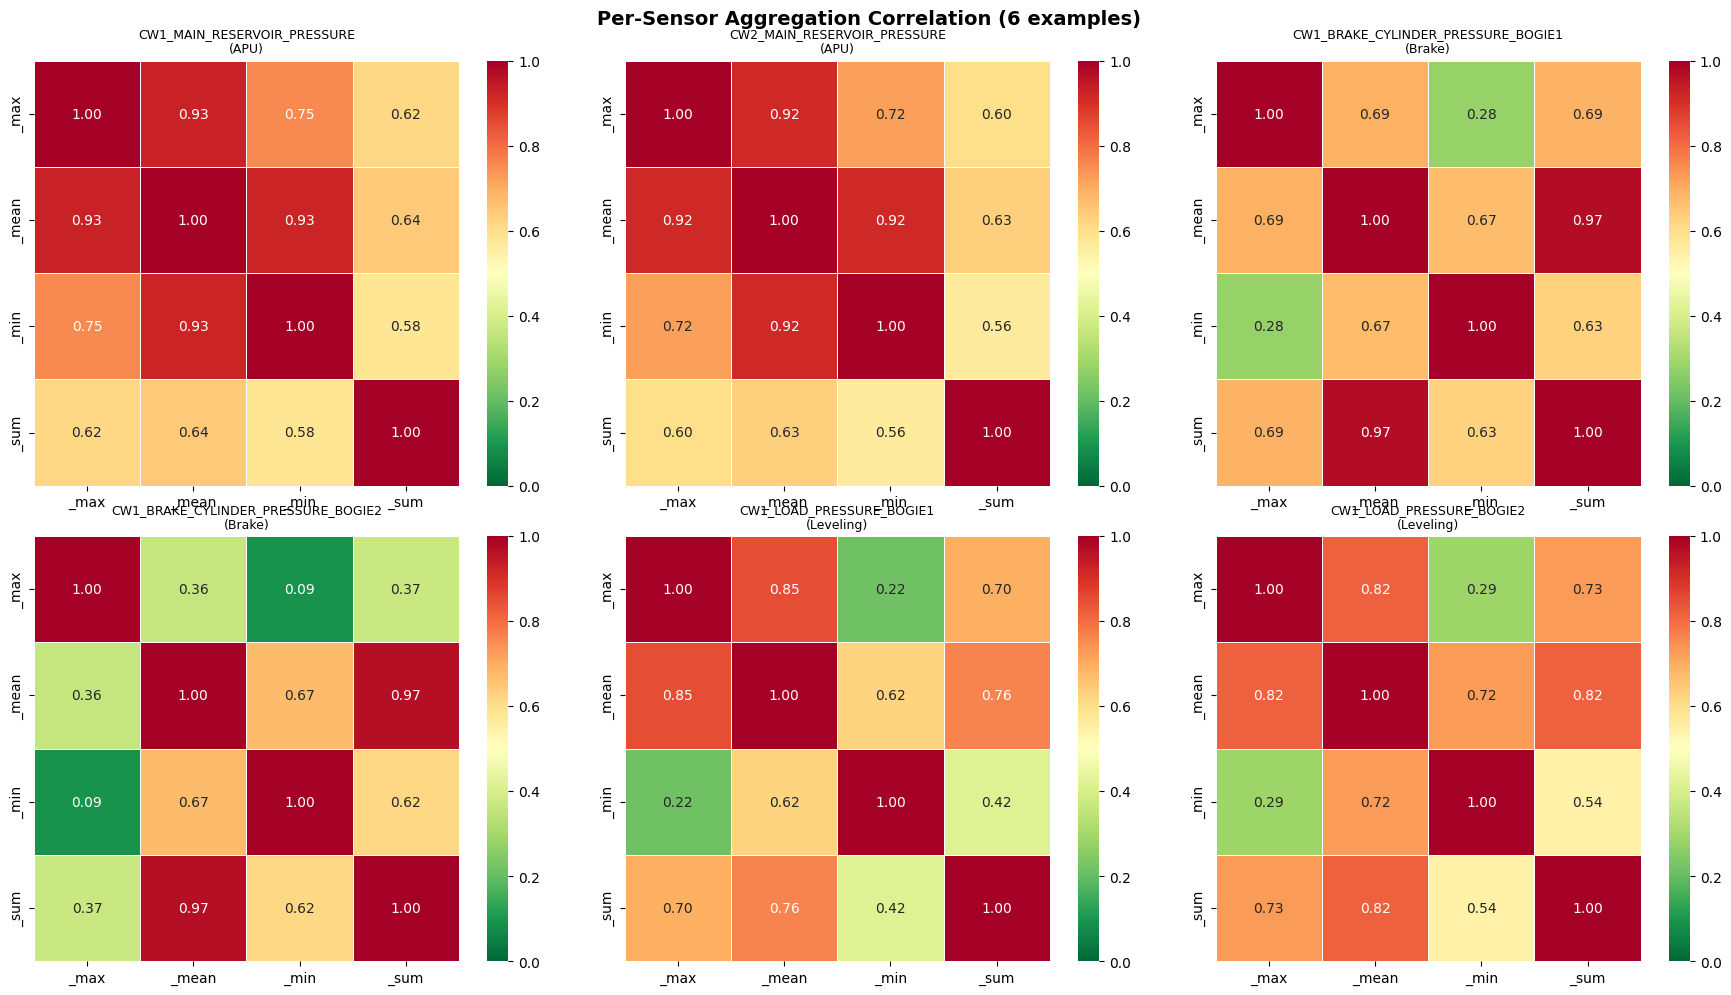


Most discriminative aggregation type (by Cohen's d):
  _min: wins for 38/95 sensors (40%)
  _max: wins for 28/95 sensors (29%)
  _flips: wins for 14/95 sensors (15%)
  _active_s: wins for 7/95 sensors (7%)
  _sum: wins for 5/95 sensors (5%)
  _mean: wins for 3/95 sensors (3%)

RECOMMENDATION FOR FEATURE REDUCTION
Current: 340 features (95 sensors: analog min/max/mean/sum, binary active_s/flips, plus 2 asset features)
  Keep all sensor features: 338 features
  Drop _sum (redundant with _mean; used in NB04): 264 features
  Drop _sum and _active_s: 243 features
  Keep best per sensor (Cohen's d): 95 features
  Keep mean + flips only: 95 features

Saved to C:\Users\Emırhan\Desktop\MASTER THESIS\Kurtulus-thesis\outputs\nb03a_artifacts\aggregation_recommendation.json


In [6]:
# ── Per-sensor breakdown: which aggregations are unique? ──
# For each sensor, show correlation matrix of its aggregations

# Pick 6 representative sensors (2 per subsystem)
example_sensors = []
seen_subs = {}
for sensor, aggs in sorted(sensor_aggs.items(), key=lambda x: -len(x[1])):
    if len(aggs) < 3:
        continue
    sub = get_subsystem(sensor + '_mean')
    if sub not in seen_subs or seen_subs[sub] < 2:
        example_sensors.append(sensor)
        seen_subs[sub] = seen_subs.get(sub, 0) + 1
    if len(example_sensors) >= 6:
        break

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for idx, sensor in enumerate(example_sensors):
    ax = axes[idx // 3, idx % 3]
    aggs = sensor_aggs[sensor]
    cols = [aggs[s] for s in sorted(aggs.keys())]
    labels = [s for s in sorted(aggs.keys())]
    corr = sample[cols].corr().abs()
    corr.index = labels
    corr.columns = labels
    sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdYlGn_r', vmin=0, vmax=1,
                ax=ax, square=True, linewidths=0.5)
    sub = get_subsystem(sensor + '_mean')
    ax.set_title(f'{sensor}\n({sub})', fontsize=9)

plt.suptitle('Per-Sensor Aggregation Correlation (6 examples)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(NB03A_OUT, 'per_sensor_agg_correlation.png'), dpi=150, bbox_inches='tight')
plt.show()

# ── Recommendation: which aggregations to keep? ──
# For each sensor, identify which aggregation has the highest Cohen's d (most discriminative)
best_agg_per_sensor = {}
for sensor, aggs in sensor_aggs.items():
    best_d = -1
    best_suf = None
    for suf, feat in aggs.items():
        d = cd_df.loc[cd_df['feature'] == feat, 'cohens_d'].values
        if len(d) > 0 and d[0] > best_d:
            best_d = d[0]
            best_suf = suf
    if best_suf:
        best_agg_per_sensor[sensor] = (best_suf, best_d)

# Count which aggregation type wins most often
from collections import Counter
winner_counts = Counter(v[0] for v in best_agg_per_sensor.values())
print('\nMost discriminative aggregation type (by Cohen\'s d):')
for suf, count in winner_counts.most_common():
    print(f'  {suf}: wins for {count}/{len(best_agg_per_sensor)} sensors ({100*count/len(best_agg_per_sensor):.0f}%)')

# Final recommendation
print(f'\n{"="*70}')
print('RECOMMENDATION FOR FEATURE REDUCTION')
print(f'{"="*70}')
print(f'Current: {len(feature_cols)} features ({len(sensor_aggs)} sensors: analog min/max/mean/sum, binary active_s/flips, plus 2 asset features)')

# Count how many features would remain with different strategies
for strategy_name, keep_sufs in [
    ('Keep all sensor features', SUFFIXES),
    ('Drop _sum (redundant with _mean; used in NB04)', ['_active_s', '_min', '_max', '_mean', '_flips']),
    ('Drop _sum and _active_s', ['_min', '_max', '_mean', '_flips']),
    ('Keep best per sensor (Cohen\'s d)', ['best']),
    ('Keep mean + flips only', ['_mean', '_flips']),
]:
    if 'best' in keep_sufs:
        n = len(best_agg_per_sensor)
    else:
        n = sum(1 for f in feature_cols if any(f.endswith(s) for s in keep_sufs))
    print(f'  {strategy_name}: {n} features')

# Save recommendation
recommendation = {
    'redundant_pairs': [(r['pair'], r['mean_corr'], r['pct_above_95']) 
                        for r in pair_summary if r['pct_above_95'] > 80],
    'best_agg_per_sensor': {k: v[0] for k, v in best_agg_per_sensor.items()},
    'winner_counts': dict(winner_counts),
}
with open(os.path.join(NB03A_OUT, 'aggregation_recommendation.json'), 'w') as f:
    json.dump(recommendation, f, indent=2)
print(f'\nSaved to {os.path.join(NB03A_OUT, "aggregation_recommendation.json")}')

## 5. Temporal Coverage

How many windows per day, where are the gaps, and at what time of day do failure windows occur? Windows exist only while the vehicle records data, so gaps are operational breaks (nights, depot time, maintenance).

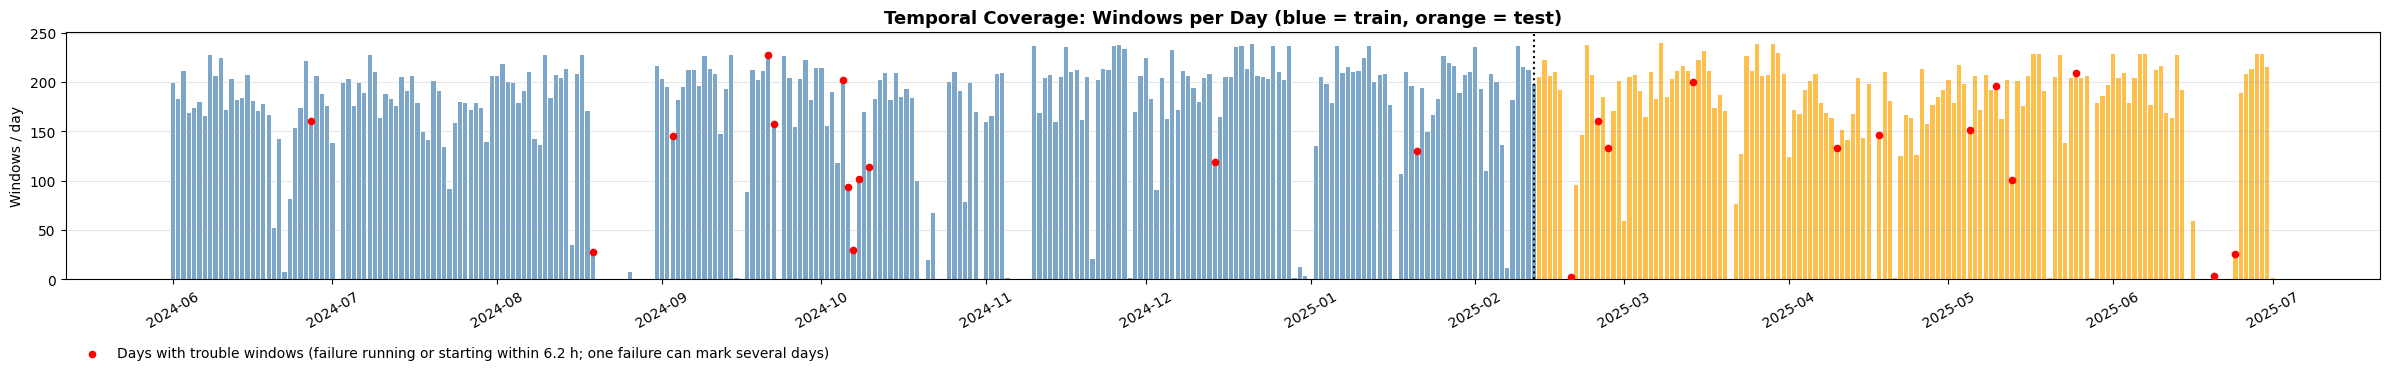

Median window gap: 350s (5.8 min)
Operational breaks (>1h): 571
  Train: 360 | Test: 211
  Median break: 2.8h | Max break: 166.7h

Windows per day: mean=178, median=196


In [7]:
feats_all['date'] = feats_all['window_end'].dt.date
daily_counts = feats_all.groupby('date').agg(
    n_windows=('label', 'count'),
    n_failure=('label', 'sum'),
    split=('split', 'first')
).reset_index()
daily_counts['date'] = pd.to_datetime(daily_counts['date'])

fig, ax = plt.subplots(figsize=(24, 4))
colors = ['steelblue' if s == 'train' else 'orange' for s in daily_counts['split']]
ax.bar(daily_counts['date'], daily_counts['n_windows'], color=colors, alpha=0.7, width=0.8)
fail_days = daily_counts[daily_counts['n_failure'] > 0]
ax.scatter(fail_days['date'], fail_days['n_windows'], color='red', s=20, zorder=5, label='Days with trouble windows (failure running or starting within 6.2 h; one failure can mark several days)')
ax.axvline(x=SPLIT_DATE, color='black', linestyle=':', linewidth=1.5)
ax.set_ylabel('Windows / day')
ax.set_title('Temporal Coverage: Windows per Day (blue = train, orange = test)', fontsize=13, fontweight='bold')
ax.legend(loc='upper left', bbox_to_anchor=(0, -0.22), frameon=False)
ax.grid(True, alpha=0.3, axis='y')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
ax.xaxis.set_major_locator(mdates.MonthLocator())
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Gaps
gaps = feats_all['window_end'].diff().dt.total_seconds()
big_gaps = gaps[gaps > 3600]  # > 1 hour
print(f'Median window gap: {gaps.median():.0f}s ({gaps.median()/60:.1f} min)')
print(f'Operational breaks (>1h): {len(big_gaps)}')
print(f'  Train: {(feats_all.loc[big_gaps.index, "split"]=="train").sum()} | Test: {(feats_all.loc[big_gaps.index, "split"]=="test").sum()}')
print(f'  Median break: {big_gaps.median()/3600:.1f}h | Max break: {big_gaps.max()/3600:.1f}h')
print(f'\nWindows per day: mean={daily_counts["n_windows"].mean():.0f}, median={daily_counts["n_windows"].median():.0f}')

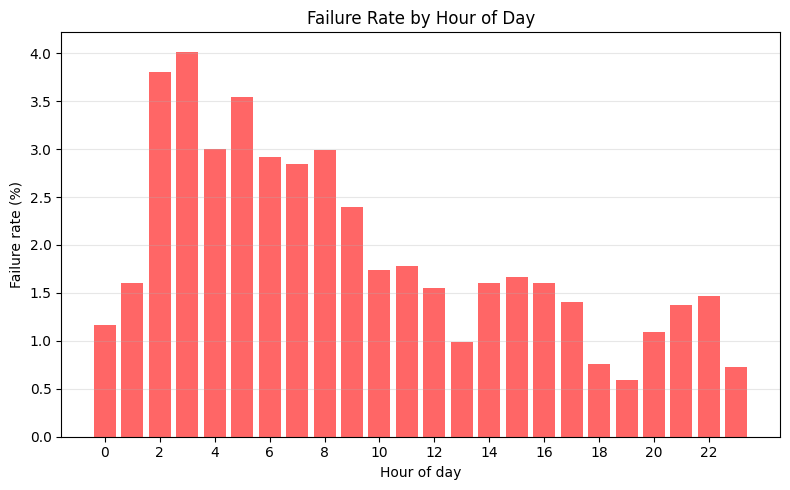

In [8]:
# ── Failure windows by time of day ──
feats_all['hour'] = feats_all['window_end'].dt.hour
hourly_fail = feats_all.groupby('hour')['label'].mean() * 100

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(hourly_fail.index, hourly_fail.values, color='red', alpha=0.6)
ax.set_xlabel('Hour of day')
ax.set_ylabel('Failure rate (%)')
ax.set_title('Failure Rate by Hour of Day')
ax.set_xticks(range(0, 24, 2))
ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

In [9]:
# ── Summary ──
print('=' * 70)
print('FEATURE DATASET EXPLORATION SUMMARY (FULL PERIOD)')
print('=' * 70)

print(f'\nPeriod: {feats_all["window_end"].min().date()} to {feats_all["window_end"].max().date()}')
print(f'Train/Test split: {SPLIT_DATE.date()}')
print(f'Total windows: {len(feats_all):,} (train: {(feats_all["split"]=="train").sum():,}, test: {(feats_all["split"]=="test").sum():,})')
print(f'Failure windows: {feats_all["label"].sum():,} ({100*feats_all["label"].mean():.2f}%)')
print(f'Features: {len(feature_cols)}')

print('\n--- Discriminability per documented sensor group (per period) ---')
print(f'Features with robust Cohen d > 0.3 (both periods): {(cd_df["cohens_d"] > 0.3).sum()} / {len(cd_df)} (pooled: {(cd_df["cohens_d_pooled"] > 0.3).sum()})')
print(f'Within-group mean |corr| (different sensors): {np.mean(within_vals):.3f}')
print(f'Cross-group mean |corr|: {np.mean(cross_vals):.3f} (ratio: {np.mean(within_vals)/np.mean(cross_vals):.1f}x)')

print('\n--- Aggregation redundancy ---')
for r in pair_summary:
    print(f'  {r["pair"]:<20} mean |r| = {r["mean_corr"]:.3f}, median = {r["median_corr"]:.3f}')

print(f'\n--- Temporal Coverage ---')
print(f'Windows/day: mean={daily_counts["n_windows"].mean():.0f}, median={daily_counts["n_windows"].median():.0f}')
print(f'Operational breaks (>1h): {len(big_gaps)}')

FEATURE DATASET EXPLORATION SUMMARY (FULL PERIOD)

Period: 2024-06-01 to 2025-07-01
Train/Test split: 2025-02-12
Total windows: 64,522 (train: 41,375, test: 23,147)
Failure windows: 1,202 (1.86%)
Features: 340

--- Discriminability per documented sensor group (per period) ---
Features with robust Cohen d > 0.3 (both periods): 234 / 340 (pooled: 268)
Within-group mean |corr| (different sensors): 0.565
Cross-group mean |corr|: 0.240 (ratio: 2.3x)

--- Aggregation redundancy ---
  _active_s vs _flips  mean |r| = 0.563, median = 0.685
  _max vs _mean        mean |r| = 0.696, median = 0.740
  _max vs _min         mean |r| = 0.383, median = 0.426
  _max vs _sum         mean |r| = 0.624, median = 0.642
  _mean vs _min        mean |r| = 0.779, median = 0.782
  _mean vs _sum        mean |r| = 0.893, median = 0.968
  _min vs _sum         mean |r| = 0.676, median = 0.621

--- Temporal Coverage ---
Windows/day: mean=178, median=196
Operational breaks (>1h): 571


## Traceability: Pipeline Position

**NB01 → NB02a → NB03a → NB04 → NB05** (clustering branch)  
**NB02a → NB02b → NB03b** (baseline branch; NB05 §4 and §7.3 compare the FCs with the baseline models)

### What this notebook provides
- Size, period split and label balance of the windowed feature dataset (no model involved)
- Cohen's d per documented sensor group, computed **per period**; the robust d (both periods) is the number to cite
- Within- vs cross-group correlation with same-sensor pairs excluded (§3)
- Aggregation redundancy (§4): mean/sum mean |r| ≈ 0.89 (median ≈ 0.97). **NB04 drops `_sum` based on this**; it is a simplification, not exact redundancy
- Temporal coverage: windows per day, operational breaks, failure windows by hour

### Outputs (`outputs/nb03a_artifacts/`)
- `aggregation_redundancy.png`, `per_sensor_agg_correlation.png`, `aggregation_recommendation.json`